In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/maharshipandya/-spotify-tracks-dataset/dataset.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/kaggle/input/datasets/maharshipandya/-spotify-tracks-dataset/dataset.csv')

df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include='all'))

Dataset shape: (114000, 21)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  1

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
count,114000.000000,114000,113999,113999,113999,114000.000000,1.140000e+05,114000,114000.000000,114000.000000,...,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000
unique,NaN,89741,31437,46589,73608,NaN,NaN,2,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,114
top,NaN,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,NaN,NaN,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,acoustic
freq,NaN,9,279,195,151,NaN,NaN,104253,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1000
mean,56999.500000,NaN,NaN,NaN,NaN,33.238535,2.280292e+05,NaN,0.566800,0.641383,...,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035,NaN
std,32909.109681,NaN,NaN,NaN,NaN,22.305078,1.072977e+05,NaN,0.173542,0.251529,...,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621,NaN
min,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000e+00,NaN,0.000000,0.000000,...,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,28499.750000,NaN,NaN,NaN,NaN,17.000000,1.740660e+05,NaN,0.456000,0.472000,...,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000,NaN
50%,56999.500000,NaN,NaN,NaN,NaN,35.000000,2.129060e+05,NaN,0.580000,0.685000,...,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000,NaN
75%,85499.250000,NaN,NaN,NaN,NaN,50.000000,2.615060e+05,NaN,0.695000,0.854000,...,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000,NaN


In [4]:
top_songs = df.sort_values(
    by='popularity',
    ascending=False
).head(10)

display(top_songs[['track_name', 'artists', 'popularity']])

,track_name,artists,popularity
81051,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100
20001,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100
51664,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,99
89411,La Bachata,Manuel Turizo,98
81210,I'm Good (Blue),David Guetta;Bebe Rexha,98
30003,I'm Good (Blue),David Guetta;Bebe Rexha,98
20008,I'm Good (Blue),David Guetta;Bebe Rexha,98
67356,La Bachata,Manuel Turizo,98
88410,La Bachata,Manuel Turizo,98
68303,La Bachata,Manuel Turizo,98


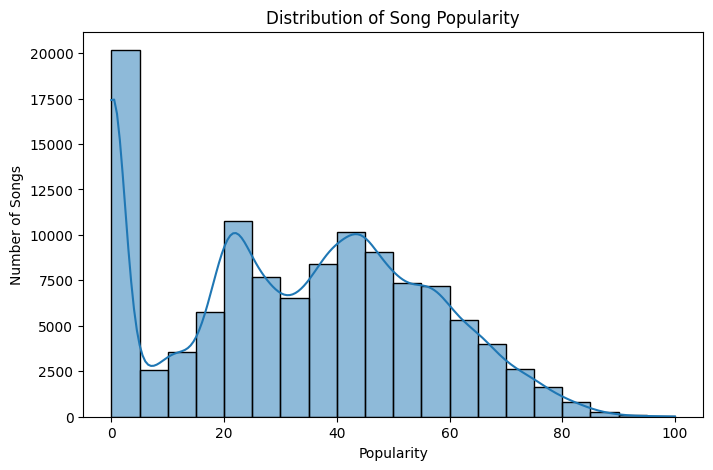

In [5]:
plt.figure(figsize=(8, 5))

sns.histplot(df['popularity'], bins=20, kde=True)

plt.title('Distribution of Song Popularity')
plt.xlabel('Popularity')
plt.ylabel('Number of Songs')

plt.show()

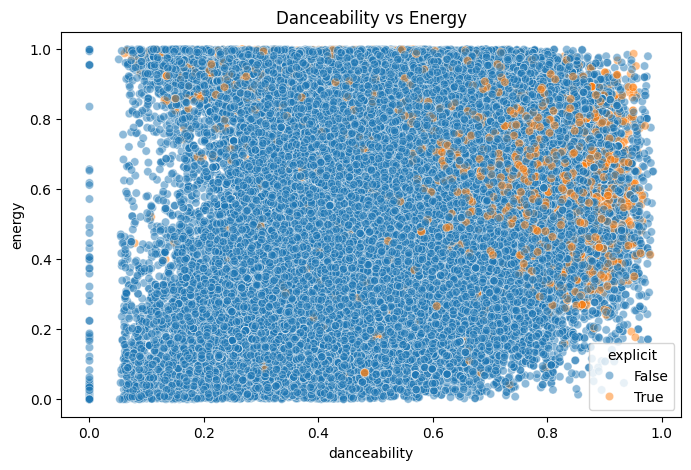

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='danceability',
    y='energy',
    hue='explicit',
    alpha=0.5
)

plt.title('Danceability vs Energy')
plt.show()

In [7]:
# Remove duplicate rows
df = df.drop_duplicates()

# Remove tracks without names
df = df.dropna(subset=['track_name'])

# Clean column names
df.columns = df.columns.str.strip()

# Reset row indices
df = df.reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Missing values:\n", df.isnull().sum())

Shape after cleaning: (113999, 21)
Missing values:
 Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [8]:
audio_features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

# Keep only features available in your dataset
audio_features = [
    col for col in audio_features
    if col in df.columns
]

print("Audio features used:", audio_features)

Audio features used: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


In [9]:
from sklearn.preprocessing import StandardScaler

# Convert selected features to numeric
X = df[audio_features].apply(
    pd.to_numeric, errors='coerce'
)

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values with column medians
X = X.fillna(X.median())

# Remove features that are entirely missing
X = X.dropna(axis=1, how='all')

# Remove constant features
X = X.loc[:, X.nunique() > 1]

audio_features = X.columns.tolist()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features used:", audio_features)
print("Prepared data shape:", X_scaled.shape)
df.head()

Features used: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
Prepared data shape: (113999, 9)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [10]:
from sklearn.neighbors import NearestNeighbors

model = NearestNeighbors(
    metric='cosine',
    algorithm='brute',
    n_jobs=-1
)

model.fit(X_scaled)

print("Recommendation model is ready!")

Recommendation model is ready!


In [11]:
def recommend_songs(song_name, top_n=5):

    matches = df[
        df['track_name'].str.casefold()
        == song_name.strip().casefold()
    ]

    if matches.empty:
        return "Song not found in the dataset."

    # Get the index of the first matching song
    song_index = matches.index[0]

    # Find only the nearest songs
    k = min(top_n + 1, len(df))

    distances, indices = model.kneighbors(
        X_scaled[song_index].reshape(1, -1),
        n_neighbors=k
    )

    results = []

    for idx, distance in zip(indices[0], distances[0]):

        # Skip the selected song itself
        if idx == song_index:
            continue

        results.append({
            'track_name': df.iloc[idx]['track_name'],
            'artists': df.iloc[idx]['artists'],
            'album_name': df.iloc[idx]['album_name'],
            'similarity': round(1 - distance, 3)
        })

        if len(results) == top_n:
            break

    return pd.DataFrame(results)

In [12]:
recommend_songs(
    "Can't Help Falling in Love",
    top_n=5
)

,track_name,artists,album_name,similarity
0,Repetitious (Zamaangard),Baaroot,From Void To Void,0.995
1,Uzun Gecələr,Rashid Beibutov,Bahar Sənsiz,0.993
2,把歌談心,林姍姍;David Ling Jr,我愛經典系列,0.993
3,In A Sentimental Mood,Ella Fitzgerald,Jazz Romance,0.992
4,In A Sentimental Mood,Ella Fitzgerald,Jazz Romance,0.992


In [13]:
recommend_songs("Comedy", top_n=10)

,track_name,artists,album_name,similarity
0,Comedy,Gen Hoshino,Comedy,1.000
1,Comedy,Gen Hoshino,Comedy,1.000
2,Comedy,Gen Hoshino,Comedy,1.000
3,Skylight,Gramatik,"Beatz & Pieces, Vol. 1",0.953
4,That Certain Female,Charlie Feathers,Kill Bill Vol. 1 Original Soundtrack (PA Version),0.930
5,Look For The Good (Single Version),Jason Mraz,Look For The Good,0.929
6,Monde de fous,Danakil,Rien ne se tait,0.929
7,Monde de fous,Danakil,Rien ne se tait,0.929
8,Blink 182,Trille,Blink 182,0.926
9,Blink 182,Trille,Blink 182,0.926
